# 05 - Pipeline Completo (2 etapas)

Avalia os dois modelos juntos, como vao rodar na deteccao ao vivo (`src/pipeline.py`):

```
fluxo -> Modelo 1 (BENIGN x Ataque) -> Modelo 2 (tipo) -> DDoS / PortScan / WebAttack / SQLInjection / Desconhecido
```

Usa o mesmo conjunto de teste dos notebooks 03 e 04, que nenhum dos modelos viu no treino.

## 1. Setup

In [1]:
import sys
sys.path.append('..')

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import time
from sklearn.metrics import classification_report, confusion_matrix

from src.data import build_dataset, train_test, split_xy
from src.pipeline import IDSPipeline, UNKNOWN

ids = IDSPipeline.load()
print('Limiar binario:', round(ids.binary_meta['threshold'], 4))
print('Limiar de confianca do tipo:', round(ids.attack_meta['threshold'], 4))

Limiar binario: 0.1622
Limiar de confianca do tipo: 0.5


## 2. Previsao no teste

In [2]:
df = build_dataset()
_, test = train_test(df)
X_test, _, tipo_real = split_xy(test)

inicio = time.perf_counter()
resultado = ids.predict(X_test)
segundos = time.perf_counter() - inicio
print(f'{len(X_test)} fluxos em {segundos:.2f}s ({len(X_test) / segundos:,.0f} fluxos/s)')
resultado.head()

90705 fluxos em 0.12s (750,951 fluxos/s)


,attack_prob,is_attack,attack_type,type_confidence
98820,9.998779e-01,1,DDoS,0.999995
439313,7.469312e-08,0,BENIGN,NaN
56244,1.406086e-06,0,BENIGN,NaN
150994,5.883431e-07,0,BENIGN,NaN
188410,2.004622e-06,0,BENIGN,NaN


## 3. Resultado final por classe

              precision    recall  f1-score   support

      BENIGN     0.9997    0.9995    0.9996     64321
        DDoS     0.9990    0.9993    0.9991     25598
    PortScan     0.9643    0.9844    0.9742       384
   WebAttack     0.9899    0.9875    0.9887       399
SQLInjection     1.0000    0.3333    0.5000         3

    accuracy                         0.9993     90705
   macro avg     0.9906    0.8608    0.8923     90705
weighted avg     0.9993    0.9993    0.9993     90705



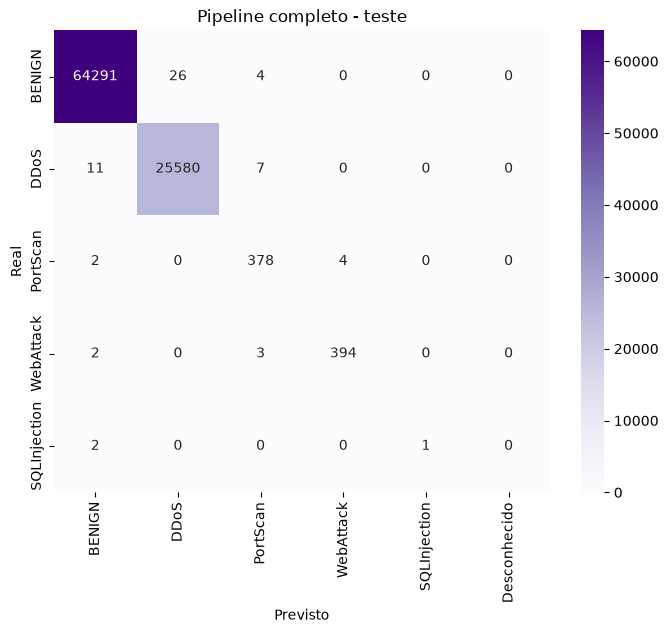

In [3]:
labels = ['BENIGN', 'DDoS', 'PortScan', 'WebAttack', 'SQLInjection']
print(classification_report(tipo_real, resultado['attack_type'], labels=labels, digits=4, zero_division=0))

cm = confusion_matrix(tipo_real, resultado['attack_type'], labels=labels + [UNKNOWN])
plt.figure(figsize=(8, 6))
sns.heatmap(cm[:len(labels)], annot=True, fmt='d', cmap='Purples',
            xticklabels=labels + [UNKNOWN], yticklabels=labels)
plt.title('Pipeline completo - teste')
plt.ylabel('Real')
plt.xlabel('Previsto')
plt.show()

## 4. Onde o pipeline erra

- **Ataques perdidos:** o Modelo 1 classificou como BENIGN.
- **Alarmes falsos:** trafego BENIGN que o Modelo 1 marcou como ataque e o tipo que o Modelo 2 deu a ele.

In [4]:
perdidos = (tipo_real != 'BENIGN') & (resultado['attack_type'] == 'BENIGN')
falsos = (tipo_real == 'BENIGN') & (resultado['attack_type'] != 'BENIGN')

print('Ataques perdidos por tipo:')
print(tipo_real[perdidos].value_counts().to_string(), '\n')
print(f'Alarmes falsos: {falsos.sum()} de {(tipo_real == "BENIGN").sum()} fluxos BENIGN '
      f'({falsos.mean() / (tipo_real == "BENIGN").mean():.4%})')
print(resultado.loc[falsos, 'attack_type'].value_counts().to_string())

Ataques perdidos por tipo:
attack_type
DDoS            11
SQLInjection     2
PortScan         2
WebAttack        2 

Alarmes falsos: 30 de 64321 fluxos BENIGN (0.0466%)
attack_type
DDoS        26
PortScan     4
